# 3.4 · A machine-learned value score

Our value score is a fixed formula: four valuation ratios, each ranked, then averaged. Damon Lee's *Build Your Own AI
Investor* (2nd edition) replaces the formula with a supervised learning model: it is trained on 18 accounting ratios
(the features) and each stock's subsequent one-year return (the target), and learns which combinations of ratios were
associated with high returns.

**The book's method and this replication:**

| Step | The book | Here |
|---|---|---|
| Features | 18 ratios: P/E, P/B, P/S, EV/EBIT, return on equity and on capital, margins, leverage, liquidity, the four Altman ratios | the same 18 ratios, point-in-time at each month end, clipped to the book's bounds |
| Target | the stock's price change over the year after its annual report | the stock's total return over the year after each month end |
| Model | gradient-boosted decision trees: 100 trees, depth 10 | the same, using scikit-learn's faster histogram-based implementation |
| Training sample | **a random half of all company-years** | **only completed years**: refitted every January on data available at the time (walk-forward) |
| Firms near default | excluded (Altman Z'' of 2 or less) | ranked last |
| Portfolio | the top 7, equal weights, held for a year | the same portfolio as notebook 3.2's second version, so only the score differs |

The change that matters is the training sample. A random train/test split lets the model learn from 2018 and then
"predict" 2015: the test set is not out of sample in time, so the backtest suffers from look-ahead bias and
overstates performance (financial returns are autocorrelated across years and stocks, so random splits leak
information). Here every prediction uses a model that could have existed on that date. Training data starts in 2006
(LSEG's statements) and the target needs a year to be observed, so the first model is fitted in January 2009.

The book's own portfolio (seven stocks held for a year) is not replicated: with one decision date a year there would
be one training date a year and no model before 2015. Holding the portfolio construction fixed makes the score the
only difference between the strategies compared.

In [1]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import factors as fx
from equity_research.research import ml
from equity_research.research.backtest import decile_returns
from equity_research.research.cache import ResearchCache
from equity_research.research.data import load_universe_data
from equity_research.research.indices import calendar_years, vendor_returns
from equity_research.research.strategy import TRAIN_FROM, StrategyConfig, factor_scores, run_strategy

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# The composite score is the weighted mean of these factors' z-scores. Only the ratios matter, and any factor
# run_strategy knows can be added (its error lists them). Equal weights are the notebook's registered trials; any
# change is a new trial, so choose the weights before seeing the results.
FACTOR_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0, "issuance": 1.0}
second = StrategyConfig(
    family="multi_factor_lo",
    universe="SP1500",
    start="2010-01-01",
    end="2024-12-31",
    factors=tuple(FACTOR_WEIGHTS.items()),
    enter=0.30,
    exit_=0.40,
    long_only=True,
    beta_neutral=False,
    weighting="market_cap",
)
data = load_universe_data(cache, second.universe, TRAIN_FROM, second.end)
sptm = vendor_returns(cache, "SPTM", total=True)

## Decile comparison of the two scores

Each month the constituents are sorted into deciles by each score, and each decile's equal-weighted next-month return
is compared with the universe average (before costs), from 2010. The learned score exists only where a model had
already been fitted; a company in Altman's distress zone ranks last.

In [2]:
members_on = data.members.reindex(data.rebalances)
learned_raw = ml.learned_value(data.ratios, data.returns, data.members, data.rebalances)
scores = {"plain value": factor_scores(data, "value"), "learned value": fx.cross_sectional_z(learned_raw, members_on)}
after = data.rebalances >= pd.Timestamp(second.start)
deciles = {name: decile_returns(s.loc[after], data.returns, data.members) for name, s in scores.items()}
display(pd.DataFrame({name: d["excess"] for name, d in deciles.items()}).T.style.format("{:+.1%}"))
print("Top tenth t:", {name: round(float(d.loc[10, "t"]), 1) for name, d in deciles.items()})
alike = scores["learned value"].loc[after].corrwith(scores["plain value"].loc[after], axis=1).mean()
print(f"How alike the two scores are (average correlation across companies each month): {alike:+.2f}")
covered = (learned_raw.notna() & members_on).sum(axis=1) / members_on.sum(axis=1)
print("Members with a learned score, each December:")
display(covered[covered.index.month == 12].to_frame("covered").T.style.format("{:.0%}"))

decile,1,2,3,4,5,6,7,8,9,10
plain value,+0.2%,-1.6%,-0.3%,-1.0%,-1.4%,+1.2%,-0.6%,+0.2%,+1.3%,+2.1%
learned value,+0.1%,-1.1%,-0.3%,-0.4%,-0.2%,-2.6%,+0.6%,+0.2%,+2.1%,+1.6%


Top tenth t: {'plain value': 0.8, 'learned value': 0.6}
How alike the two scores are (average correlation across companies each month): +0.31
Members with a learned score, each December:


,2006-12-29 00:00:00,2007-12-31 00:00:00,2008-12-31 00:00:00,2009-12-31 00:00:00,2010-12-31 00:00:00,2011-12-30 00:00:00,2012-12-31 00:00:00,2013-12-31 00:00:00,2014-12-31 00:00:00,2015-12-31 00:00:00,2016-12-30 00:00:00,2017-12-29 00:00:00,2018-12-31 00:00:00,2019-12-31 00:00:00,2020-12-31 00:00:00,2021-12-31 00:00:00,2022-12-30 00:00:00,2023-12-29 00:00:00,2024-12-31 00:00:00
covered,0%,0%,0%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%


## Inside a portfolio

First each score on its own, in the same portfolio as notebook 3.2's second version (the top 30 % by score, held until
it leaves the top 40 %, cap-weighted). Then the second version itself, with the learned score in place of the
formula value score. Every run is registered; the value-only portfolios form a new family of trials.

In [3]:
alone = replace(second, family="value_only_lo")
learned_five = tuple(("ml_value", w) if n == "value" else (n, w) for n, w in FACTOR_WEIGHTS.items())
configs = {
    "plain value alone": replace(alone, factors=(("value", 1.0),)),
    "learned value alone": replace(alone, factors=(("ml_value", 1.0),)),
    "second version (plain value)": second,
    "second version, learned value instead": replace(second, factors=learned_five),
}
runs = {name: run_strategy(cache, cfg, engine=engine) for name, cfg in configs.items()}
ACTIVE = {
    "cagr": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "beta": "{:.2f}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({name: r.metrics for name, r in runs.items()}).T[list(ACTIVE)].style.format(ACTIVE))
print("Registered as research runs", {name: r.run_id for name, r in runs.items()})
print("Trials so far:", {cfg.family: runs[name].metrics["trials"] for name, cfg in configs.items()})

,cagr,sharpe,max_drawdown,beta,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
plain value alone,11.1%,0.62,-46%,1.11,-2.5%,8.1%,-0.25,7%,1.3
learned value alone,13.5%,0.78,-32%,1.07,-0.4%,4.1%,-0.06,23%,2.7
second version (plain value),13.6%,0.87,-34%,0.89,-0.3%,3.7%,-0.14,1%,1.2
"second version, learned value instead",13.8%,0.88,-32%,0.90,-0.2%,3.1%,-0.11,2%,1.2


Registered as research runs {'plain value alone': 106, 'learned value alone': 107, 'second version (plain value)': 108, 'second version, learned value instead': 109}
Trials so far: {'value_only_lo': 2, 'multi_factor_lo': 12}


Each year: the strategy's return minus SPTM's


,plain value alone,learned value alone,second version (plain value),"second version, learned value instead"
trade_date,,,,
2010,-0.8%,+0.1%,-5.2%,-4.4%
2011,-2.7%,+2.3%,+7.2%,+7.0%
2012,+2.3%,-5.8%,-0.5%,-1.2%
2013,+1.0%,-0.8%,-1.2%,-2.3%
2014,-1.8%,-1.7%,-0.2%,+0.1%
2015,-5.2%,-1.5%,-0.5%,+0.7%
2016,+11.4%,+4.1%,-1.5%,-3.9%
2017,-2.1%,+3.9%,+1.2%,+1.8%
2018,-7.1%,-3.1%,+1.6%,+2.5%


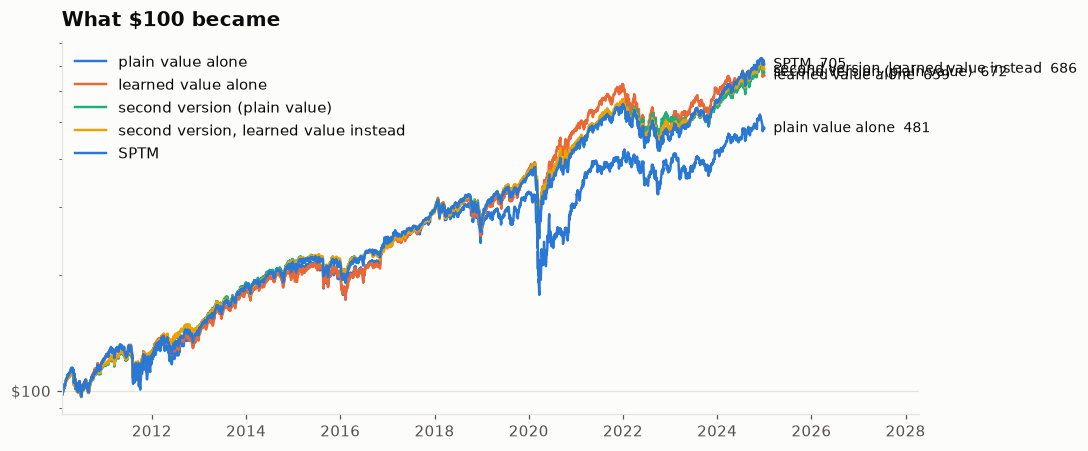

In [4]:
fig = charts.growth({name: r.backtest.net for name, r in runs.items()} | {"SPTM": sptm}, "What $100 became")
ahead = pd.DataFrame(
    {
        name: calendar_years({name: r.backtest.net, "SPTM": sptm}).pipe(lambda y, n=name: y[n] - y["SPTM"])
        for name, r in runs.items()
    }
)
print("Each year: the strategy's return minus SPTM's")
display(ahead.style.format("{:+.1%}", na_rep=""))

## Findings

* **On its own, the learned score beats formula value - but not through its top decile.** In the same portfolio it
  returned 13.5 % a year against formula value's 11.1 %, with a maximum drawdown of 32 % against 46 %, and trailed
  SPTM by 0.4 % a year against 2.5 % (information ratios -0.06 and -0.25). Yet its top decile's excess return
  (+1.6 % a year, t 0.6) is now slightly *below* formula value's (+2.1 %, t 0.8), and both are within sampling error:
  the portfolio's advantage comes from what it avoids, not from a better top decile.
* **It is not a value score.** Its correlation with formula value is only 0.3: the book's 18 features mix valuation
  with profitability, leverage and liquidity, so the model tilts towards profitable, financially sound companies -
  closer to a quality score. That is why it avoided value's worst years (2020: +11.1 points against SPTM, where
  formula value lost 23.8; 2023: +1.3 against -14.7) and also missed its best (2016 and 2022, when formula value
  gained 11 points or more against +4.1 and -5.1). Its own worst year is 2024 (-15.4 points), when a handful of
  mega-caps carried SPTM.
* **In the five-factor portfolio it adds almost nothing.** With the learned score in place of formula value, the
  portfolio returned 13.8 % a year and trailed SPTM by 0.2 % (information ratio -0.11), against 13.6 %, -0.3 % and
  -0.14 with formula value. What the model adds over formula value - a quality tilt and avoiding distressed firms -
  the quality, low-volatility and momentum factors largely provide already.
* **None of this is statistically convincing.** The best deflated active Sharpe ratio is 23 % (the learned score
  alone), far below the 95 % that would count as evidence. The book's random split would have reported better numbers
  by letting the model learn from the very years it was tested on.

These numbers are from the rerun of 31 October 2026, after the additional accounting items were loaded (LSEG's annual
cash flows and other items now fill the years before the SEC's XBRL data, so the model trains on fuller features).
The run before that showed the learned score at 13.7 % a year with a top-decile edge of +2.7 % - the change shows how
sensitive a learned score is to its inputs.

An earlier run still showed the learned score 1.4 % a year ahead of SPTM inside the portfolio. That was a data error:
LSEG restates a company's historical share counts to today's share basis, which made Alphabet's market capitalisation
twenty times too large and gave it a third of the portfolio in 2015. Market capitalisations now use each share
class's own point-in-time share count.

## Glossary

* **Supervised learning** - fitting a model that maps inputs (features) to a known outcome (the target) from
  examples, instead of specifying the rule by hand.
* **Gradient-boosted trees** - an ensemble of shallow decision trees fitted sequentially, each one fitted to the
  residual errors of the ensemble so far; flexible enough to capture non-linear effects and interactions.
* **Walk-forward validation** - training only on data available before each prediction date, as the model would have
  had to be used in practice.
* **Overfitting** - a model that fits noise in its training data and so performs worse on new data than in sample.
* **Altman Z''** - Altman's (1995) bankruptcy-prediction score for non-manufacturers, a weighted sum of four
  balance-sheet ratios; 2 or less is the distress zone.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.2.